# Desafio 1 — Predição de renda

Estimar a renda mensal a partir dos dados cadastrais e do comportamento financeiro. O modelo entregue é uma regressão linear. O alvo é `Renda`.


In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
SEMENTE = 42
CAMINHO_BASE = Path("datasets/clientes.csv")


## Exploração

A leitura usa o caminho `datasets/clientes.csv`. A exploração inicial olha tipos, amostra e distribuição. Os histogramas cobrem as numéricas, inclusive a renda. A matriz de correlação inclui a renda para mostrar o que anda junto com o alvo.


In [2]:
base = pd.read_csv(CAMINHO_BASE)
base.info()
display(base.head())
display(base.describe())


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID_Cliente           2000 non-null   int64  
 1   Nome                 2000 non-null   str    
 2   Idade                2000 non-null   int64  
 3   Escolaridade         2000 non-null   str    
 4   Tempo_Emprego        2000 non-null   int64  
 5   Estado_Civil         2000 non-null   str    
 6   Dependentes          2000 non-null   int64  
 7   Score_Credito        2000 non-null   int64  
 8   Gasto_Mensal_Cartao  2000 non-null   float64
 9   Investimentos        2000 non-null   float64
 10  Dividas              2000 non-null   float64
 11  Renda                2000 non-null   float64
 12  Categoria_Cliente    2000 non-null   str    
dtypes: float64(4), int64(5), str(4)
memory usage: 203.3 KB


,ID_Cliente,Nome,Idade,Escolaridade,Tempo_Emprego,Estado_Civil,Dependentes,Score_Credito,Gasto_Mensal_Cartao,Investimentos,Dividas,Renda,Categoria_Cliente
0,1,Bruno Ferreira Gomes,22,Fundamental,1,Divorciado,1,210,451.73,882.43,17089.75,3530.80,Bronze
1,2,Bruno Barbosa Cardoso,59,Médio,5,Casado,2,482,1569.73,6989.56,6537.04,6087.50,Prata
2,3,Beatriz Correia Souza,52,Fundamental,10,Casado,1,585,468.87,6300.54,1169.29,3249.91,Prata
3,4,Mariana Lopes Vieira,41,Fundamental,7,Solteiro,2,661,442.77,12161.10,1433.53,3709.71,Prata
4,5,Fernanda Fernandes Lima,40,Superior,12,Casado,2,351,1457.27,8030.33,39111.05,11635.89,Bronze


,ID_Cliente,Idade,Tempo_Emprego,Dependentes,Score_Credito,Gasto_Mensal_Cartao,Investimentos,Dividas,Renda
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1000.500000,43.988000,9.298000,1.125000,577.743000,1638.345210,43115.564090,11977.963435,7607.712285
std,577.494589,15.373029,7.708236,1.054007,256.468402,986.718718,63476.727346,12783.020918,2912.175650
min,1.000000,18.000000,0.000000,0.000000,0.000000,136.740000,68.980000,457.320000,1100.000000
25%,500.750000,31.000000,3.000000,0.000000,371.000000,932.612500,5338.372500,3305.862500,5403.947500
50%,1000.500000,44.000000,8.000000,1.000000,578.500000,1380.035000,16283.300000,6690.870000,7508.235000
75%,1500.250000,57.000000,14.000000,2.000000,783.000000,2091.642500,55160.980000,16129.487500,9647.935000
max,2000.000000,70.000000,36.000000,5.000000,1000.000000,6148.340000,747759.240000,89608.390000,17429.410000


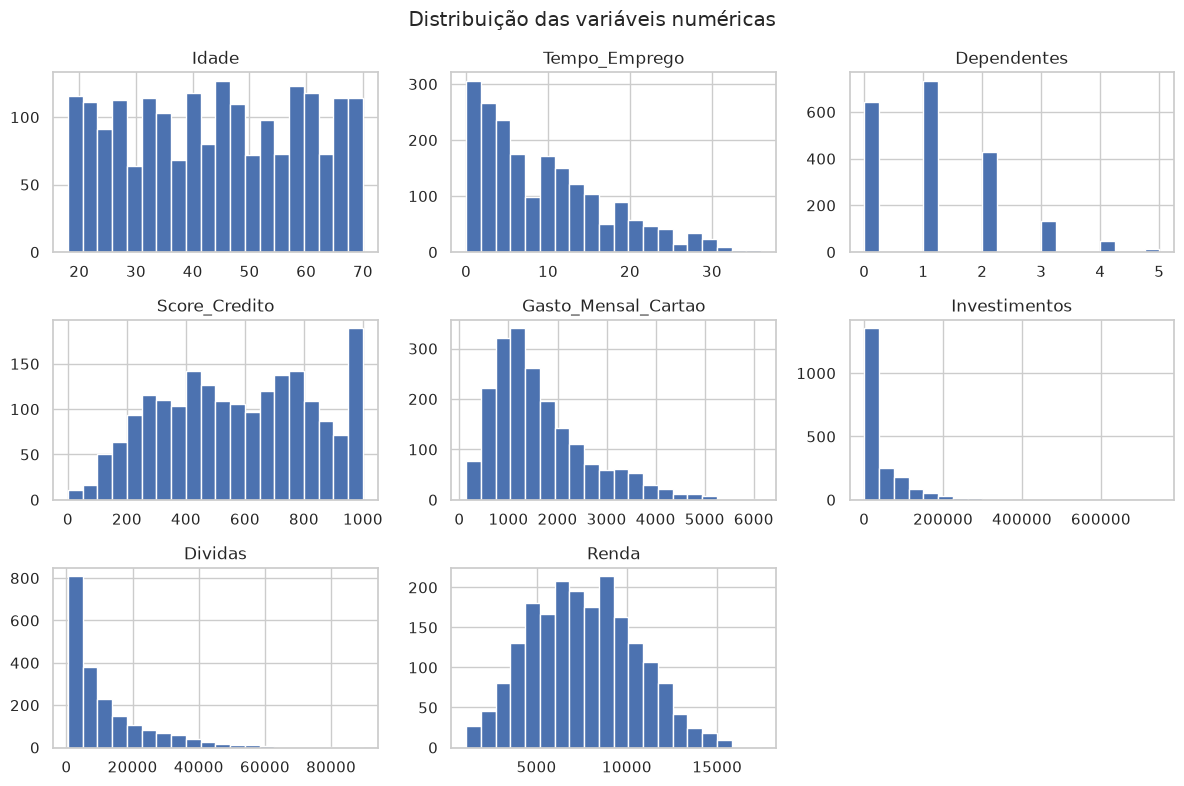

In [3]:
colunas_numericas = [
    "Idade",
    "Tempo_Emprego",
    "Dependentes",
    "Score_Credito",
    "Gasto_Mensal_Cartao",
    "Investimentos",
    "Dividas",
    "Renda",
]

base[colunas_numericas].hist(figsize=(12, 8), bins=20)
plt.suptitle("Distribuição das variáveis numéricas")
plt.tight_layout()
plt.show()


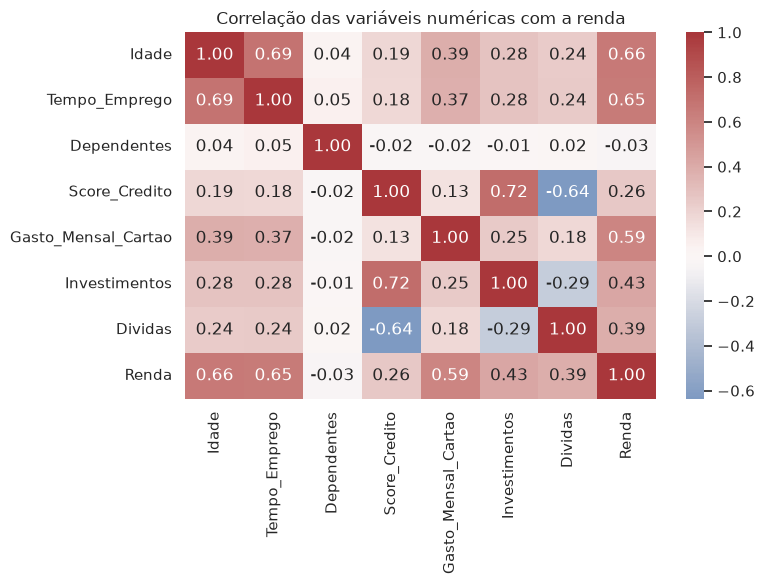

In [4]:
correlacao = base[colunas_numericas].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlação das variáveis numéricas com a renda")
plt.tight_layout()
plt.show()


A ANOVA compara a renda média entre os níveis de cada categórica. `Escolaridade` e `Estado_Civil` seguem para o modelo. `Categoria_Cliente` entra só nesta comparação: a categoria é um rótulo comercial ligado à renda, e usá-la como feature tornaria a regressão e a classificação circulares.


In [5]:
for coluna in ["Escolaridade", "Estado_Civil", "Categoria_Cliente"]:
    grupos = [grupo["Renda"].to_numpy() for _, grupo in base.groupby(coluna, observed=True)]
    estatistica, valor_p = stats.f_oneway(*grupos)
    print(f"{coluna}: F={estatistica:.2f}  p={valor_p:.4g}")


Escolaridade: F=421.38  p=4.986e-212
Estado_Civil: F=8.45  p=1.409e-05
Categoria_Cliente: F=110.25  p=4.736e-66


## Pré-processamento e modelo

Saem `ID_Cliente`, `Nome` e `Categoria_Cliente`. O split é 80/20, com `random_state=42`, antes de qualquer ajuste.

As numéricas passam por `StandardScaler` e as categóricas por `OneHotEncoder(drop="first")`, os dois dentro do pipeline. O encoder e o scaler só enxergam o treino, também na validação cruzada, porque o `cross_val_score` reajusta o pipeline a cada fold. `drop="first"` evita a duplicação das dummies na regressão: o coeficiente de cada categoria é a diferença, em reais, contra a categoria de referência. O coeficiente de uma numérica é o efeito de um desvio-padrão, também em reais.


In [6]:
base_modelo = base.drop(columns=["ID_Cliente", "Nome", "Categoria_Cliente"])
colunas_numericas_modelo = [
    "Idade",
    "Tempo_Emprego",
    "Dependentes",
    "Score_Credito",
    "Gasto_Mensal_Cartao",
    "Investimentos",
    "Dividas",
]
colunas_categoricas_modelo = ["Escolaridade", "Estado_Civil"]

X = base_modelo.drop(columns=["Renda"])
y = base_modelo["Renda"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=SEMENTE
)

modelo_renda = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    ("numericas", StandardScaler(), colunas_numericas_modelo),
                    ("categoricas", OneHotEncoder(drop="first"), colunas_categoricas_modelo),
                ]
            ),
        ),
        ("regressao", LinearRegression()),
    ]
)
modelo_renda.fit(X_treino, y_treino)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressao', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Idade','Escolaridade','Tempo_Emprego',...,'Gasto_Mensal_Cartao', 'Investimentos','Dividas']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically 

## Avaliação

RMSE e MAE ficam em reais. O R² do teste é a métrica de referência (pelo menos 0,70). O R² médio sai de 5 folds no treino.


In [7]:
predito = modelo_renda.predict(X_teste)
rmse = np.sqrt(mean_squared_error(y_teste, predito))
mae = mean_absolute_error(y_teste, predito)
r2 = r2_score(y_teste, predito)
r2_cv = cross_val_score(modelo_renda, X_treino, y_treino, cv=5, scoring="r2")

print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R²: {r2:.3f}")
print(f"R² médio (5 folds): {r2_cv.mean():.3f}")


RMSE: 995.63
MAE: 808.95
R²: 0.873
R² médio (5 folds): 0.872


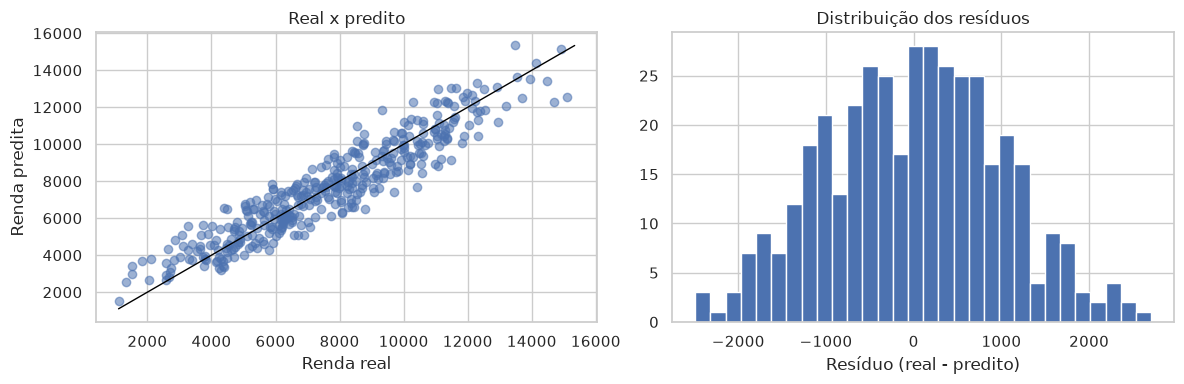

In [8]:
residuos = y_teste.to_numpy() - predito
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].scatter(y_teste, predito, alpha=0.55)
limites = [min(y_teste.min(), predito.min()), max(y_teste.max(), predito.max())]
eixos[0].plot(limites, limites, color="black", linewidth=1)
eixos[0].set_xlabel("Renda real")
eixos[0].set_ylabel("Renda predita")
eixos[0].set_title("Real x predito")
eixos[1].hist(residuos, bins=30)
eixos[1].set_xlabel("Resíduo (real - predito)")
eixos[1].set_title("Distribuição dos resíduos")
plt.tight_layout()
plt.show()


In [9]:
nomes_features = modelo_renda.named_steps["preprocessor"].get_feature_names_out()
coeficientes = modelo_renda.named_steps["regressao"].coef_
tabela_coeficientes = pd.DataFrame(
    {"feature": nomes_features, "coeficiente": coeficientes}
)
tabela_coeficientes["feature"] = (
    tabela_coeficientes["feature"]
    .str.replace("numericas__", "", regex=False)
    .str.replace("categoricas__", "", regex=False)
)
tabela_coeficientes["magnitude"] = tabela_coeficientes["coeficiente"].abs()
tabela_coeficientes = tabela_coeficientes.sort_values("magnitude", ascending=False)
display(tabela_coeficientes.reset_index(drop=True))


,feature,coeficiente,magnitude
0,Escolaridade_Pós,3280.711991,3280.711991
1,Escolaridade_Superior,1704.224111,1704.224111
2,Dividas,938.082951,938.082951
3,Tempo_Emprego,797.377461,797.377461
4,Score_Credito,735.314566,735.314566
5,Idade,677.418320,677.418320
6,Escolaridade_Médio,573.550961,573.550961
7,Estado_Civil_Solteiro,-568.900422,568.900422
8,Gasto_Mensal_Cartao,429.231519,429.231519
9,Estado_Civil_Divorciado,-406.389804,406.389804


In [10]:
joblib.dump(modelo_renda, "modelo_renda.pkl")


['modelo_renda.pkl']

## Conclusões

A referência de cada categórica é o primeiro nível, em ordem, omitido pelo `drop="first"`. Nesta base, escolaridade usa Fundamental e estado civil usa Casado. Os coeficientes numéricos estão em reais por desvio-padrão. Os coeficientes de categoria estão em reais contra essa referência. A ordenação por magnitude junta as duas escalas, e a leitura precisa manter essa diferença.


In [11]:
encoder = modelo_renda.named_steps["preprocessor"].named_transformers_["categoricas"]
referencias = [niveis[0] for niveis in encoder.categories_]
print(
    "Referências do one-hot:",
    ", ".join(f"{coluna}={nivel}" for coluna, nivel in zip(colunas_categoricas_modelo, referencias)),
)
print(
    f"No teste, o R² foi {r2:.3f}, o RMSE foi R$ {rmse:,.2f} e o MAE foi R$ {mae:,.2f}. "
    f"A renda média do teste é R$ {y_teste.mean():,.2f}, então o MAE corresponde a "
    f"{mae / y_teste.mean():.1%} desse valor. "
    f"A validação cruzada de 5 folds no treino teve R² médio de {r2_cv.mean():.3f}."
)
print(
    f"A média dos resíduos no teste foi R$ {residuos.mean():,.2f}. "
    "O gráfico de real contra predito e o histograma dos resíduos mostram esse erro em torno de zero."
)
print("Maiores magnitudes:")
display(tabela_coeficientes.head(5).reset_index(drop=True))


Referências do one-hot: Escolaridade=Fundamental, Estado_Civil=Casado
No teste, o R² foi 0.873, o RMSE foi R$ 995.63 e o MAE foi R$ 808.95. A renda média do teste é R$ 7,654.46, então o MAE corresponde a 10.6% desse valor. A validação cruzada de 5 folds no treino teve R² médio de 0.872.
A média dos resíduos no teste foi R$ -4.82. O gráfico de real contra predito e o histograma dos resíduos mostram esse erro em torno de zero.
Maiores magnitudes:


,feature,coeficiente,magnitude
0,Escolaridade_Pós,3280.711991,3280.711991
1,Escolaridade_Superior,1704.224111,1704.224111
2,Dividas,938.082951,938.082951
3,Tempo_Emprego,797.377461,797.377461
4,Score_Credito,735.314566,735.314566
